# 3-Layer Neural Network Regressor

This model will predict how much a play helps the offense using only information available before the snap (`ppa`).

We use this because it is the most flexible model in the project, the hidden layer can learn combinations of features by itself. It is the complex, time-consuming model in the project (class iv in the rubric).

How it is evaluated (same as the XGBoost and other regression models).
- Train on the 20 training games, test once on the 6 held-out games; plays from one game never appear in both.
- Same 24 features as the other regression models. Neural networks need scaled inputs, so the numeric features are standardized, `down` and `period` are one-hot encoded, and the missing values are filled in.
- Hyperparameters are tuned **inside the training set only**, with 5-fold cross-validation grouped by game (`GroupKFold` on `gameId`) and chosen on RMSE.
- Neural networks start from random weights, so I also repeat the final fit with 10 different random starts to show how much the result depends on luck.

In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TARGET = "ppa"

project_dir = Path.cwd().parent
fig_dir = project_dir / "reports" / "figures"
table_dir = project_dir / "reports" / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# same colors as the other regression figures
NN_COLOR, NULL_COLOR, ACTUAL_COLOR = "tab:purple", "tab:gray", "black"

## Load data

In [2]:
df = pd.read_csv(project_dir / "data" / "processed" / "model_df.csv").dropna(subset=[TARGET])   # one play has no ppa

with open(project_dir / "data" / "processed" / "regression_feature_lists_after_eda.json") as f:
    feature_info = json.load(f)["regression"]

features = feature_info["features"]
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]
binary_features = feature_info["binary"]

# Same train/test split as the other models: whole games, never single plays
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

X_train, y_train = train_df[features], train_df[TARGET]
X_test, y_test = test_df[features], test_df[TARGET]

# Game ids for cross-validation inside the training set
groups_train = train_df["gameId"]

# Sanity checks
assert set(train_df["gameId"]).isdisjoint(set(test_df["gameId"])), "a game appears in both train and test"
assert not {"yardsGained", "ppa", "playType", "playText", "is_pass"} & set(features), "post-snap column in features"

print(f"Training: {X_train.shape[0]} plays from {train_df['gameId'].nunique()} games")
print(f"Testing:  {X_test.shape[0]} plays from {test_df['gameId'].nunique()} games")
print(f"Features: {len(features)}  |  training mean ppa {y_train.mean():.3f}, testing mean ppa {y_test.mean():.3f}")

Training: 1394 plays from 20 games
Testing:  378 plays from 6 games
Features: 24  |  training mean ppa 0.283, testing mean ppa 0.242


## Preprocessing

- Numeric: median imputation (plus a missing-value indicator), then standardize.
- `down` and `period`: one-hot encode.
- Binary play history (`prev_call_1..3`) has gaps at the start of games, so most-frequent imputation plus an indicator.
- The target `ppa` is also standardized while training (and converted back for predictions), so the network does not have to learn the 0.28 average from scratch in a few epochs.

All imputers and scalers sit inside the Pipeline, so they are fit on training data only.

In [3]:
numeric_missing = ["prev_yards", "pass_rate_last5", "pass_rate_game_so_far",
                   "team_prior_pass_rate", "team_prior_pass_rate_down"]
binary_missing = ["prev_call_1", "prev_call_2", "prev_call_3"]
binary_no_missing = [c for c in binary_features if c not in binary_missing]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))])
binary_missing_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent", add_indicator=True))])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("binary_missing", binary_missing_pipeline, binary_missing),
        ("binary", "passthrough", binary_no_missing),
    ],
    remainder="drop",
)

In [4]:
def evaluate(model, X, y):
    pred = model.predict(X)
    return {"R2": r2_score(y, pred), "MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred))}, pred


def bootstrap_gain_by_game(y, pred, null_pred, games, n_boot=2000, seed=RANDOM_STATE):
    """RMSE improvement over the null model, resampling whole games (plays in a game are correlated)."""
    rng = np.random.default_rng(seed)
    y, pred, null_pred, games = map(np.asarray, (y, pred, null_pred, games))
    ids = np.unique(games)
    gains = []
    for _ in range(n_boot):
        pick = rng.choice(ids, size=len(ids), replace=True)
        idx = np.concatenate([np.where(games == g)[0] for g in pick])
        gains.append(np.sqrt(np.mean((y[idx] - null_pred[idx]) ** 2)) - np.sqrt(np.mean((y[idx] - pred[idx]) ** 2)))
    return np.mean(gains), np.percentile(gains, [2.5, 97.5])


def permutation_table(model, X, y, n_repeats=30):
    """How much the test RMSE goes up when one original feature is shuffled."""
    r = permutation_importance(model, X, y, scoring="neg_root_mean_squared_error", n_repeats=n_repeats,
                               random_state=RANDOM_STATE, n_jobs=-1)
    return (pd.DataFrame({"Feature": X.columns, "RMSE increase": r.importances_mean, "Std": r.importances_std})
              .sort_values("RMSE increase", ascending=False).reset_index(drop=True))

## Reference model

The Null Model predicts the training mean for every play. This is the number the network has to beat.

In [5]:
null_model = DummyRegressor(strategy="mean").fit(X_train, y_train)
null_train, _ = evaluate(null_model, X_train, y_train)
null_test, null_pred_test = evaluate(null_model, X_test, y_test)

display(pd.DataFrame({"Null Model (train)": null_train, "Null Model (test)": null_test}).T.round(4))

,R2,MAE,RMSE
Null Model (train),0.000,0.9652,1.3460
Null Model (test),-0.001,0.9356,1.2841


## Tuning with cross-validation by game

| Hyperparameter | Meaning | Values tried |
|---|---|---|
| `hidden_layer_sizes` | Number of nodes in the single hidden layer | 4, 8, 16, 32 |
| `activation` | Function applied at the hidden nodes | `relu`, `tanh` |
| `alpha` | L2 penalty on the weights; larger = simpler network, less overfitting | 0.1, 1, 10, 30, 100 |
| `max_iter` | Number of epochs (full passes over the training plays). Too few underfits; too many memorizes the training plays | 25, 50, 100, 200, 400 |

Fixed choices: Adam optimizer, learning rate 0.001, and training runs for exactly `max_iter` epochs.

The signal in this data is weak (see the XGBoost notebook), so I expect the best settings to be small and heavily penalized. I tried much larger alpha values than the classification network for that reason (the first run picked alpha = 10, the edge of the grid, so I extended it to 30 and 100).

In [6]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # stopping at max_iter is intended here

nn_pipeline = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", MLPRegressor(solver="adam", learning_rate_init=0.001,
                                   early_stopping=False, n_iter_no_change=1000,    # train for exactly max_iter epochs
                                   random_state=RANDOM_STATE)),
    ]),
    transformer=StandardScaler(),     # standardize ppa while training
)

P = "regressor__regressor__"
param_grid = {
    P + "hidden_layer_sizes": [(4,), (8,), (16,), (32,)],     # one hidden layer = 3-layer network
    P + "activation": ["relu", "tanh"],
    P + "alpha": [0.1, 1.0, 10.0, 30.0, 100.0],
    P + "max_iter": [25, 50, 100, 200, 400],
}

cv = GroupKFold(n_splits=5)          # each fold holds out whole games

search = GridSearchCV(nn_pipeline, param_grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, refit=True)

t0 = time.perf_counter()
search.fit(X_train, y_train, groups=groups_train)
tuning_seconds = time.perf_counter() - t0

best_params = {k.replace(P, ""): v for k, v in search.best_params_.items()}
print(f"Tried {len(search.cv_results_['params'])} settings x 5 folds in {tuning_seconds:.0f} s")
print("Best settings:", best_params)
print(f"Best cross-validated RMSE (training games only): {-search.best_score_:.4f}")

# Null model under the same folds so the comparison is fair
null_cv = [np.sqrt(np.mean((y_train.iloc[va] - y_train.iloc[tr].mean()) ** 2))
           for tr, va in cv.split(X_train, y_train, groups_train)]
print(f"Null model cross-validated RMSE:                {np.mean(null_cv):.4f}")

Tried 200 settings x 5 folds in 69 s
Best settings: {'activation': 'relu', 'alpha': 10.0, 'hidden_layer_sizes': (16,), 'max_iter': 200}
Best cross-validated RMSE (training games only): 1.3324
Null model cross-validated RMSE:                1.3464


In [7]:
cv_table = pd.DataFrame(search.cv_results_)
cv_table = cv_table.rename(columns={
    P.join(["param_", "hidden_layer_sizes"]): "hidden_nodes",
    P.join(["param_", "activation"]): "activation",
    P.join(["param_", "alpha"]): "alpha",
    P.join(["param_", "max_iter"]): "epochs",
    "mean_test_score": "CV RMSE (mean)",
    "std_test_score": "CV RMSE (std across folds)",
})
cv_table["hidden_nodes"] = cv_table["hidden_nodes"].apply(lambda t: t[0])
cv_table["CV RMSE (mean)"] = -cv_table["CV RMSE (mean)"]
cv_table = cv_table[["hidden_nodes", "activation", "alpha", "epochs", "CV RMSE (mean)",
                     "CV RMSE (std across folds)", "rank_test_score"]].sort_values("rank_test_score")
cv_table.to_csv(table_dir / "regression_nn_cv_results.csv", index=False)

print("Top 8 settings:")
display(cv_table.head(8).round(4))
print("Worst setting for comparison:")
display(cv_table.tail(1).round(4))

# Is the winner at the edge of the grid?
tried = {"hidden_nodes": [4, 8, 16, 32], "alpha": [0.1, 1.0, 10.0, 30.0, 100.0], "epochs": [25, 50, 100, 200, 400]}
for name, values in tried.items():
    best_value = cv_table.iloc[0][name]
    if best_value in (min(values), max(values)):
        print(f"Note: best {name} = {best_value:g} is at the edge of the values tried; consider extending the grid.")

Top 8 settings:


,hidden_nodes,activation,alpha,epochs,CV RMSE (mean),CV RMSE (std across folds),rank_test_score
53,16,relu,10.0,200,1.3324,0.0727,1
54,16,relu,10.0,400,1.3335,0.0723,2
48,8,relu,10.0,200,1.3342,0.0726,3
49,8,relu,10.0,400,1.3347,0.0713,4
43,4,relu,10.0,200,1.3354,0.0703,5
147,8,tanh,10.0,100,1.3365,0.0730,6
59,32,relu,10.0,400,1.3365,0.0711,7
58,32,relu,10.0,200,1.3366,0.0722,8


Worst setting for comparison:


,hidden_nodes,activation,alpha,epochs,CV RMSE (mean),CV RMSE (std across folds),rank_test_score
19,32,relu,0.1,400,1.5868,0.1694,200


## Final model performance

In [8]:
best_nn = search.best_estimator_
net = best_nn.regressor_.named_steps["regressor"]

# Time one clean fit with the chosen settings
t0 = time.perf_counter()
clone(best_nn).fit(X_train, y_train)
fit_seconds = time.perf_counter() - t0

n_inputs = best_nn.regressor_.named_steps["preprocessor"].transform(X_train.head(1)).shape[1]
print(f"Architecture: {n_inputs} input nodes -> {net.hidden_layer_sizes[0]} hidden nodes ({net.activation}) -> 1 output node")
print(f"Trained for {net.n_iter_} epochs; one fit takes {fit_seconds:.2f} s")

train_m, pred_train = evaluate(best_nn, X_train, y_train)
test_m, pred_test = evaluate(best_nn, X_test, y_test)

print()
print(f"R2:   {test_m['R2']:.4f}")
print(f"MAE:  {test_m['MAE']:.4f}")
print(f"RMSE: {test_m['RMSE']:.4f}")
print()

compare = pd.DataFrame({"Null Model": null_test, "Neural Network": test_m}).T
display(compare.round(4))

gap = pd.DataFrame({
    "RMSE": [train_m["RMSE"], -search.best_score_, test_m["RMSE"]],
    "R2": [train_m["R2"], np.nan, test_m["R2"]],
}, index=["Training plays (fit on these)", "Cross-validation (unseen games, training set)", "Test games (unseen)"])
print("Does it overfit? Compare how it does on plays it has seen vs plays it has not:")
display(gap.round(4))

Architecture: 38 input nodes -> 16 hidden nodes (relu) -> 1 output node
Trained for 200 epochs; one fit takes 0.39 s

R2:   0.0357
MAE:  0.8930
RMSE: 1.2604



,R2,MAE,RMSE
Null Model,-0.0010,0.9356,1.2841
Neural Network,0.0357,0.8930,1.2604


Does it overfit? Compare how it does on plays it has seen vs plays it has not:


,RMSE,R2
Training plays (fit on these),1.3007,0.0661
"Cross-validation (unseen games, training set)",1.3324,NaN
Test games (unseen),1.2604,0.0357


### How much does the result depend on luck?

Two checks.
- Refit with 10 different random starting weights and look at the spread of the test results.
- Resample the 6 test games (with replacement) and see how much the RMSE improvement over the Null Model changes. If the interval includes 0, we cannot say the network beats the Null Model.

In [9]:
seed_rows = []
for s in range(10):
    m = clone(best_nn)
    m.regressor.set_params(regressor__random_state=s)
    m.fit(X_train, y_train)
    seed_rows.append(evaluate(m, X_test, y_test)[0])
seeds = pd.DataFrame(seed_rows)
print("Test results over 10 random starts:")
display(seeds.agg(["mean", "std", "min", "max"]).round(4))

gain, (lo, hi) = bootstrap_gain_by_game(y_test, pred_test, null_pred_test, test_df["gameId"])
print(f"RMSE improvement over Null Model: {gain:+.4f}  (95% interval from resampling games: {lo:+.4f} to {hi:+.4f})")

Test results over 10 random starts:


,R2,MAE,RMSE
mean,0.0336,0.9000,1.2618
std,0.0022,0.0029,0.0014
min,0.0292,0.8933,1.2593
max,0.0374,0.9032,1.2647


RMSE improvement over Null Model: +0.0241  (95% interval from resampling games: +0.0048 to +0.0425)


## Training curve and predictions

The training curve is the loss on the training plays after each epoch (in standardized units). It always goes down; what matters is whether the test results get better too, which is what the tuning above checks.

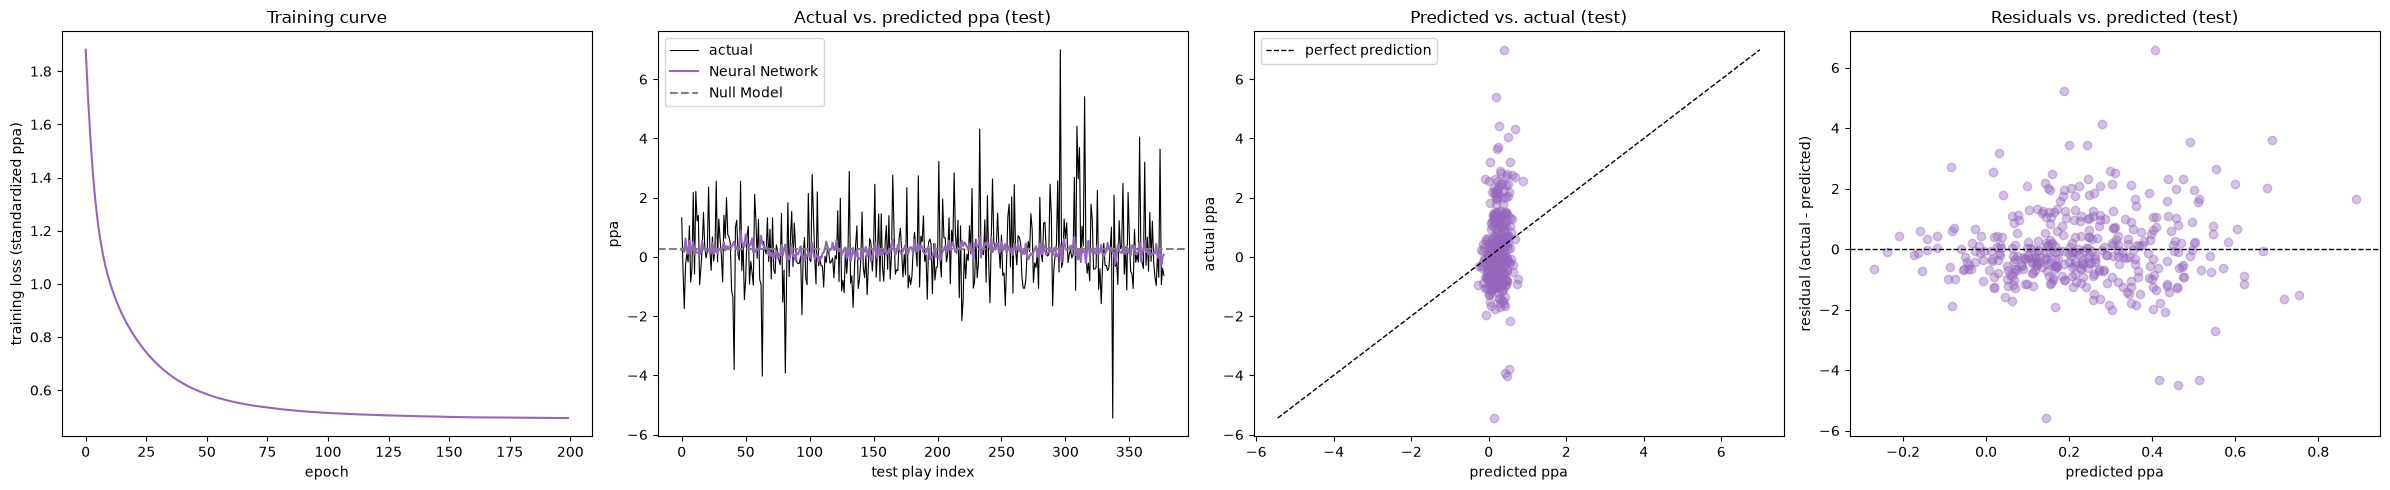

range of predictions: -0.271 to 0.890 | range of actual: -5.44 to 7.00


In [10]:
fig, ax = plt.subplots(1, 4, figsize=(24, 5))

ax[0].plot(net.loss_curve_, color=NN_COLOR)
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss (standardized ppa)")
ax[0].set_title("Training curve")

ax[1].plot(y_test.values, color=ACTUAL_COLOR, lw=0.8, label="actual")
ax[1].plot(pred_test, color=NN_COLOR, lw=1.5, label="Neural Network")
ax[1].axhline(null_model.constant_.item(), color=NULL_COLOR, ls="--", label="Null Model")
ax[1].set_xlabel("test play index"); ax[1].set_ylabel("ppa"); ax[1].legend()
ax[1].set_title("Actual vs. predicted ppa (test)")

ax[2].scatter(pred_test, y_test, alpha=0.4, color=NN_COLOR)
lim = [y_test.min(), y_test.max()]
ax[2].plot(lim, lim, "k--", lw=1, label="perfect prediction")
ax[2].set_xlabel("predicted ppa"); ax[2].set_ylabel("actual ppa"); ax[2].legend()
ax[2].set_title("Predicted vs. actual (test)")

ax[3].scatter(pred_test, y_test - pred_test, alpha=0.4, color=NN_COLOR)
ax[3].axhline(0, color="k", ls="--", lw=1)
ax[3].set_xlabel("predicted ppa"); ax[3].set_ylabel("residual (actual - predicted)")
ax[3].set_title("Residuals vs. predicted (test)")

plt.tight_layout()
plt.savefig(fig_dir / "regression_nn_diagnostics.png", dpi=150)
plt.show()
print(f"range of predictions: {pred_test.min():.3f} to {pred_test.max():.3f} | range of actual: {y_test.min():.2f} to {y_test.max():.2f}")

## Feature importance

Permutation importance on the test games: shuffle one feature and see how much the RMSE gets worse. A value near 0 or below means the network is not using that feature in a way that helps on new games.

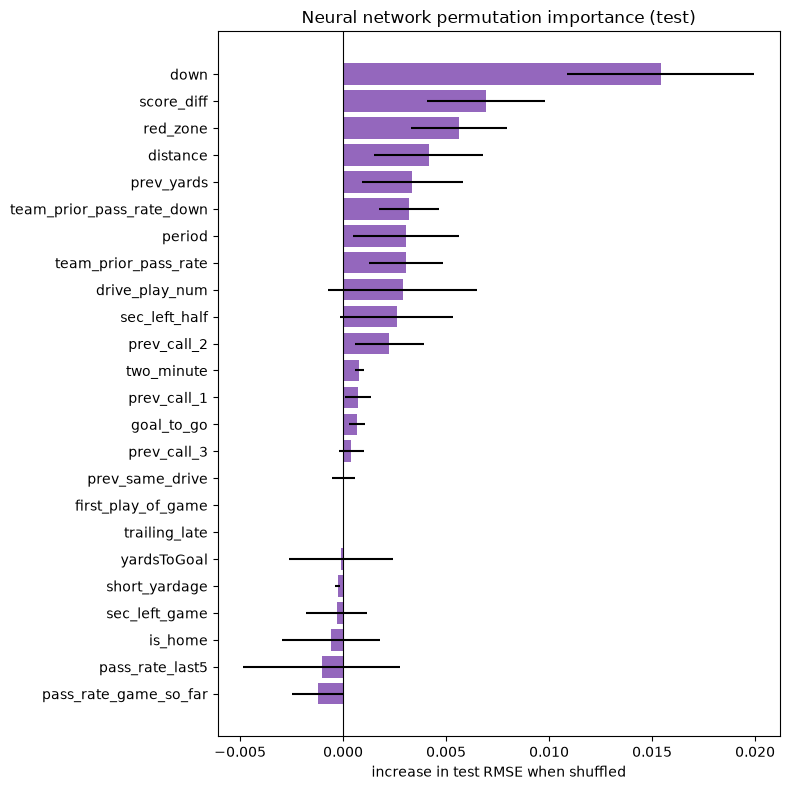

,Feature,RMSE increase,Std
0,down,0.0154,0.0046
1,score_diff,0.0069,0.0029
2,red_zone,0.0056,0.0023
3,distance,0.0042,0.0026
4,prev_yards,0.0034,0.0024
5,team_prior_pass_rate_down,0.0032,0.0015
6,period,0.0031,0.0026
7,team_prior_pass_rate,0.0031,0.0018
8,drive_play_num,0.0029,0.0036
9,sec_left_half,0.0026,0.0027


In [11]:
perm = permutation_table(best_nn, X_test, y_test)
perm.to_csv(table_dir / "regression_nn_permutation_importance.csv", index=False)

p = perm.sort_values("RMSE increase")
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(p["Feature"], p["RMSE increase"], xerr=p["Std"], color=NN_COLOR)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("increase in test RMSE when shuffled")
ax.set_title("Neural network permutation importance (test)")
plt.tight_layout()
plt.savefig(fig_dir / "regression_nn_permutation_importance.png", dpi=150)
plt.show()
display(perm.head(10).round(4))

## Save results

In [12]:
results = pd.DataFrame([
    {"model": "NullModel", "split": "train", **null_train},
    {"model": "NullModel", "split": "test", **null_test},
    {"model": "Neural Network", "split": "train", **train_m},
    {"model": "Neural Network", "split": "test", **test_m},
])
results.to_csv(table_dir / "regression_results_neural_network.csv", index=False)

details = {
    "best_params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_params.items()},
    "cv_rmse": float(-search.best_score_),
    "null_cv_rmse": float(np.mean(null_cv)),
    "seed_test_rmse_mean": float(seeds["RMSE"].mean()), "seed_test_rmse_std": float(seeds["RMSE"].std()),
    "bootstrap_rmse_gain": float(gain), "bootstrap_ci": [float(lo), float(hi)],
}
with open(table_dir / "regression_neural_network_details.json", "w") as f:
    json.dump(details, f, indent=2)
results.round(4)

,model,split,R2,MAE,RMSE
0,NullModel,train,0.0000,0.9652,1.3460
1,NullModel,test,-0.0010,0.9356,1.2841
2,Neural Network,train,0.0661,0.9327,1.3007
3,Neural Network,test,0.0357,0.8930,1.2604
